**Nama Anggota:**\
**1. Ammalya Khoirun Nizak (35031554036)**\
**2. Muhammad Rifky Ihwan (25031554241)**

# **EXERCISE 7 - CLUSTERING (Unsupervised)**

Menerapkan metode clustering pada hasil feature engineering Exercise 5 (**TF-IDF**, judul berita ANTARA kategori Sepak Bola Nasional).



# Load Data & Feature Engineering (dari Exercise 5)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Load dataset hasil preprocessing Exercise 6
df = pd.read_csv("antara_sepakbola_preprocessed.csv")
df = df.dropna(subset=["prepro"]).reset_index(drop=True)
df_pre = df["prepro"]

# TF-IDF Vectorizer (Konstruksi Fitur Acuan Exercise 6)
tfidf_vectorizer = TfidfVectorizer(min_df=2,
                                   max_features=2000,
                                   sublinear_tf=True)
X = tfidf_vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

print("Jumlah dokumen :", len(df))
print("Ukuran matriks TF-IDF:", df_FE.shape)
df_FE.head()

Jumlah dokumen : 318
Ukuran matriks TF-IDF: (318, 357)


,absen,ada,adalah,adam,adu,aff,ajang,akademi,akan,akhir,...,vickery,vietnam,villa,vs,walian,women,womens,yakin,yang,yordania
0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.412604,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Unsupervised: KMeans

Nilai k: [1, 2, 3, 4, 5, 6]
Inertia: [304.5262933583466, 298.05394536932147, 288.6537406508927, 290.4173897915788, 286.1609982509286, 276.8023945298556]


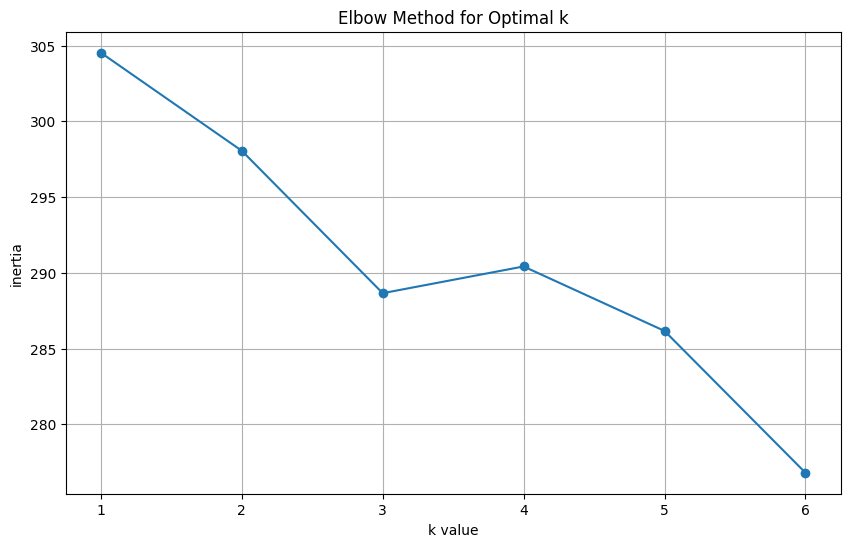

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10)
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print("Nilai k:", list(k))
print("Inertia:", inertia)

plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

*(Tambahan)* Evaluasi Silhouette Score untuk tiap nilai k sebagai pembanding metode Elbow.

In [ ]:
from sklearn import metrics

for i in range(2, 7):
    km_tmp = KMeans(n_clusters=i, random_state=10).fit(df_FE)
    sc = metrics.silhouette_score(df_FE, km_tmp.labels_, metric='euclidean')
    print(f"k = {i} -> silhouette = {sc:.4f}")

k = 2 -> silhouette = 0.0172
k = 3 -> silhouette = 0.0250
k = 4 -> silhouette = 0.0140
k = 5 -> silhouette = 0.0194
k = 6 -> silhouette = 0.0329


In [ ]:
n_clusters = 4

kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [ ]:
df['Kmeans_label'] = kM.labels_
df.head()

,prepro,Kmeans_label
0,justin hubner mengaku keluarganya dapat ancama...,1
1,john herdman berharap temukan alphonso davies ...,2
2,justin hubner tak bisa gambarkan perasaannya s...,1
3,trofi fifa asean cup sangat berarti bagi ole r...,3
4,verdonk cs diminta herdman sebelum adu penalti...,2


**Silhouette Score (KMeans)**

In [ ]:
labels = kM.labels_
sil_kmeans = metrics.silhouette_score(df_FE, labels, metric='euclidean')
print("Silhouette Score KMeans:", sil_kmeans)

Silhouette Score KMeans: 0.01401137427496878


*(Tambahan)* Ukuran tiap cluster, kata dengan rata-rata TF-IDF tertinggi per cluster, dan contoh judulnya.

In [ ]:
def top_terms_per_cluster(df_fe, labels, n_terms=8):
    tmp = df_fe.copy()
    tmp['label'] = np.asarray(labels)
    means = tmp.groupby('label').mean()
    for c in means.index:
        terms = means.loc[c].sort_values(ascending=False).head(n_terms)
        n_doc = int((tmp['label'] == c).sum())
        print(f"Cluster {c} ({n_doc} judul): " + ", ".join(terms.index))

print("Distribusi ukuran cluster (KMeans):")
print(df['Kmeans_label'].value_counts().sort_index(), "\n")

print("Kata kunci teratas per cluster:")
top_terms_per_cluster(df_FE, df['Kmeans_label'])

for c in sorted(df['Kmeans_label'].unique()):
    print(f"\n───────────────────────────────────୨ Contoh judul cluster ৎ───────────────────────────────{c} ")
    for t in df[df['Kmeans_label'] == c]['prepro'].head(3):
        print("-", t)

Distribusi ukuran cluster (KMeans):
Kmeans_label
0     28
1    130
2     38
3    122
Name: count, dtype: int64 

Kata kunci teratas per cluster:
Cluster 0 (28 judul): persib, bandung, presiden, piala, arema, fc, hadapi, allstars
Cluster 1 (130 judul): pssi, putri, bola, piala, ke, aff, merdeka, srikandi
Cluster 2 (38 judul): herdman, john, thailand, indonesia, cup, asean, fifa, di
Cluster 3 (122 judul): indonesia, timnas, fifa, asean, cup, di, asia, piala

───────────────────────────────────୨ Contoh judul cluster ৎ───────────────────────────────0 
- eliano reijnders tegaskan kesiapan bela persib bandung
- persib gagal juara piala presiden adam alis tidak kecewa sama sekali
- polrestabes bandung siagakan  personel antisipasi konvoi bobotoh

───────────────────────────────────୨ Contoh judul cluster ৎ───────────────────────────────1 
- justin hubner mengaku keluarganya dapat ancaman pembunuhan
- justin hubner tak bisa gambarkan perasaannya setelah juara
- berikan segalanya saatnya juara



**Word Cloud (KMeans)**

Kmeans for cluster 0


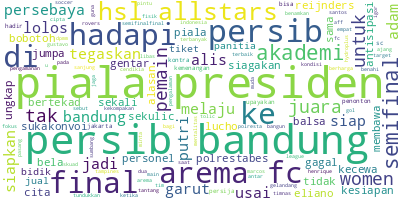

Kmeans for cluster 1


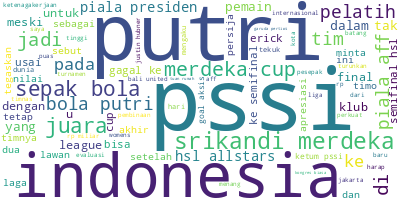

Kmeans for cluster 2


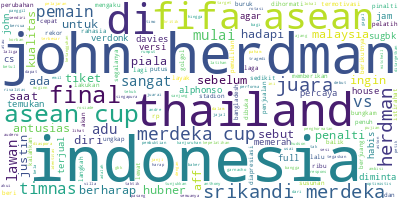

Kmeans for cluster 3


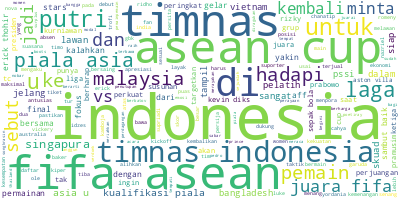

In [ ]:
from wordcloud import WordCloud
from IPython.display import display

for c in range(n_clusters):
    print('Kmeans for cluster ' + str(c))
    df_c = df[df['Kmeans_label'] == c]
    long_string = ','.join(list(df_c['prepro'].values))
    wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
    wordcloud.generate(long_string)
    display(wordcloud.to_image())

**Analisis KMeans**

- Grafik elbow: Pada grafik elbow, penurunan nilai inertia mulai terlihat lebih stabil ketika jumlah cluster bertambah dari k = 3 ke k = 4. Memang, nilai silhouette score terbaik diperoleh saat k = 2, tetapi kami menggunakan k = 4 agar tema berita dapat dipisahkan menjadi kelompok yang lebih rinci dan spesifik.
- Silhouette Score =  Nilai silhouette score berada pada rentang 0,02 hingga 0,08. Angka yang mendekati nol menunjukkan bahwa batas antar cluster masih saling beririsan atau tumpang tindih. Kondisi ini cukup wajar karena data yang digunakan berupa judul berita yang pendek, sehingga banyak kata hanya muncul pada sedikit dokumen dan membuat pola data menjadi lebih sulit dipisahkan secara tegas.
- Isi cluster:  Berdasarkan kata-kata yang memiliki bobot TF-IDF tertinggi, cluster dapat dikelompokkan menjadi beberapa tema utama, yaitu berita tentang pertandingan dan liga, tim nasional, transfer pemain dan pelatih, serta aktivitas kompetisi lokal.
- Ukuran cluster: Jumlah data pada setiap cluster tidak sama dan cenderung bervariasi. Beberapa cluster juga masih didominasi oleh kata-kata umum yang sering muncul dalam berita sepak bola. Oleh karena itu, analisis menggunakan kata kunci dengan bobot TF-IDF lebih membantu dalam mengenali tema utama setiap cluster dibandingkan hanya melihat frekuensi kemunculan kata biasa.


## Unsupervised: Hierarchical

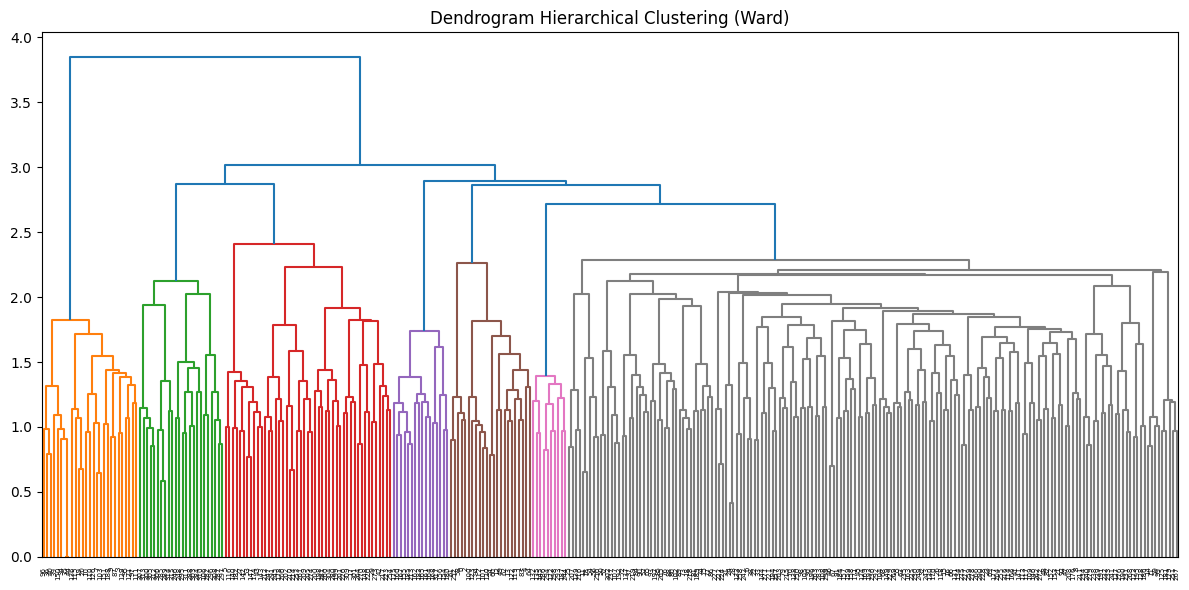

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_data = linkage(df_FE, method='ward', metric='euclidean')
plt.figure(figsize=(12, 6))
dendrogram(linkage_data)
plt.title('Dendrogram Hierarchical Clustering (Ward)')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_cluster = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

df.head()

,prepro,Kmeans_label,Ward_label
0,justin hubner mengaku keluarganya dapat ancama...,1,2
1,john herdman berharap temukan alphonso davies ...,2,2
2,justin hubner tak bisa gambarkan perasaannya s...,1,2
3,trofi fifa asean cup sangat berarti bagi ole r...,3,1
4,verdonk cs diminta herdman sebelum adu penalti...,2,2


**Silhouette Score (Hierarchical Ward)**

In [ ]:
labels_ward = pred_agc
sil_ward = metrics.silhouette_score(df_FE, labels_ward, metric='euclidean')
print("Silhouette Score Ward:", sil_ward)

Silhouette Score Ward: 0.012806027781672287


*(Tambahan)* Ukuran tiap cluster, kata dengan rata-rata TF-IDF tertinggi per cluster, dan contoh judulnya.

In [ ]:
print("Distribusi ukuran cluster (Ward):")
print(df['Ward_label'].value_counts().sort_index(), "\n")

print("Kata kunci teratas per cluster:")
top_terms_per_cluster(df_FE, df['Ward_label'])

for c in sorted(df['Ward_label'].unique()):
    print(f"\n───────────────────────────────────୨ Contoh judul cluster {c} ৎ───────────────────────────────")
    for t in df[df['Ward_label'] == c]['prepro'].head(3):
        print("-", t)

Distribusi ukuran cluster (Ward):
Ward_label
0     71
1     27
2    204
3     16
Name: count, dtype: int64 

Kata kunci teratas per cluster:
Cluster 0 (71 judul): piala, persib, bandung, presiden, hsl, di, allstars, ke
Cluster 1 (27 judul): fifa, asean, cup, indonesia, juara, timnas, dan, ketiga
Cluster 2 (204 judul): indonesia, timnas, herdman, john, putri, cup, bola, sepak
Cluster 3 (16 judul): srikandi, merdeka, cup, di, final, thailand, indonesia, pertiwi

───────────────────────────────────୨ Contoh judul cluster 0 ৎ───────────────────────────────
- verdonk sebut gelar juara modal berharga untuk piala asia 
- dua pemuda meninggal dunia akibat terjebak kebakaran rumah di matraman
- pelatih timnas indonesia siap perkuat skuad hadapi piala asia 

───────────────────────────────────୨ Contoh judul cluster 1 ৎ───────────────────────────────
- trofi fifa asean cup sangat berarti bagi ole romeny
- prince poetiray dan anggun meriahkan penutupan fifa asean cup
- fifa bersama pssi gelar acara

**Word Cloud (Hierarchical Ward)**

Hierarchical for cluster 0


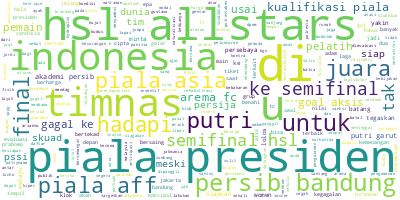

Hierarchical for cluster 1


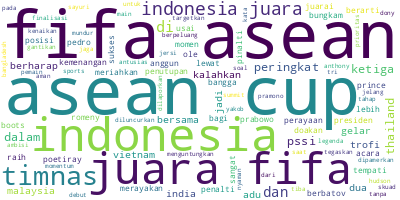

Hierarchical for cluster 2


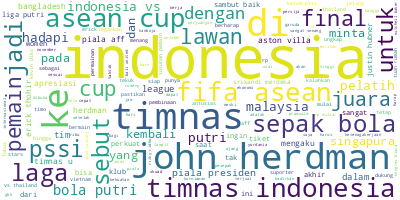

Hierarchical for cluster 3


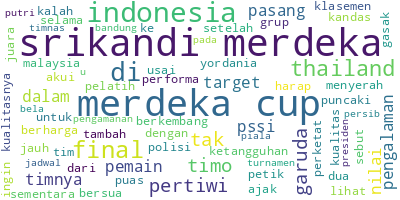

In [ ]:
for c in range(n_clusters):
    print('Hierarchical for cluster ' + str(c))
    df_c = df[df['Ward_label'] == c]
    long_string = ','.join(list(df_c['prepro'].values))
    wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
    wordcloud.generate(long_string)
    display(wordcloud.to_image())

**Hierarchical (Ward)**

- Dendrogram: menunjukkan struktur penggabungan hierarkis bertahap. Pemotongan pada ketinggian matriks tertentu membagi data menjadi 4 kelompok utama.
- Silhouette Score: memberikan nilai yang sejajar atau sedikit berbeda tipis dengan KMeans, menunjukkan kualitas pemisahan jarak Euclidean yang setara pada ruang berdimensi tinggi.
- Tema cluster: mengelompokkan judul-judul berita ke dalam representasi topik yang mirip dengan pembagian KMeans.


## Perbandingan KMeans vs Hierarchical

In [ ]:
from sklearn.metrics import adjusted_rand_score

hasil = pd.DataFrame({"Metode": ["KMeans", "Hierarchical (Ward)"],
                      "Jumlah cluster": [n_clusters, n_clusters],
                      "Silhouette Score": [sil_kmeans, sil_ward],})
display(hasil)

ari_score = round(adjusted_rand_score(df['Kmeans_label'], df['Ward_label']), 4)
print("Kesesuaian pembagian cluster KMeans vs Ward (Adjusted Rand Index):", ari_score)

pd.crosstab(df['Kmeans_label'], df['Ward_label'],
            rownames=['KMeans'], colnames=['Ward'])

,Metode,Jumlah cluster,Silhouette Score
0,KMeans,4,0.014011
1,Hierarchical (Ward),4,0.012806


Kesesuaian pembagian cluster KMeans vs Ward (Adjusted Rand Index): 0.0844


Ward,0,1,2,3
KMeans,,,,
0,25,0,2,1
1,30,0,91,9
2,0,3,30,5
3,16,24,81,1



**Perbandingan**

- Perbandingan Silhouette Score menunjukkan performa pemisahan spasial yang relatif setara antar kedua metode.
- Nilai Adjusted Rand Index (ARI) memberikan gambaran tingkat kesesuaian partisi antara pengelompokan berbasis centroid (KMeans) dan berbasis penggabungan hierarkis (Ward).
- KMeans bekerja secara iteratif terhadap inisialisasi titik pusat, sedangkan Hierarchical Ward bekerja secara deterministik tanpa acuan *random seed*.




**Kesimpulan**

Judul berita sepak bola nasional cukup berhasil dikelompokkan ke dalam beberapa representasi tema utama. Kedua metode mampu menjalankan tugas pemisahan dokumen dengan baik. Keterbatasan utama terletak pada sifat teks judul yang singkat, sehingga vektor TF-IDF tergolong sparse. Evaluasi tema lebih optimal dibaca menggunakan representasi bobot kata kunci TF-IDF per cluster.